In [718]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
data_path = Path('../data/raw/ml-latest-small')

In [719]:
links = pd.read_csv(data_path / 'links.csv')
movies = pd.read_csv(data_path / 'movies.csv')
ratings = pd.read_csv(data_path / 'ratings.csv')
tags = pd.read_csv(data_path / 'tags.csv')

In [720]:
#movies
print(movies.head())
print(movies.info()) 
print(movies.shape)

   movieId                               title  \
0        1                    Toy Story (1995)   
1        2                      Jumanji (1995)   
2        3             Grumpier Old Men (1995)   
3        4            Waiting to Exhale (1995)   
4        5  Father of the Bride Part II (1995)   

                                        genres  
0  Adventure|Animation|Children|Comedy|Fantasy  
1                   Adventure|Children|Fantasy  
2                               Comedy|Romance  
3                         Comedy|Drama|Romance  
4                                       Comedy  
<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 228.5 KB
None
(9742, 3)


In [721]:
# links
print(links.shape)
print(links.info())
print(links.head())
display(links[links.isnull().any(axis=1)])
links[links['tmdbId'].duplicated(keep=False)].sort_values('tmdbId')

(9742, 3)
<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   movieId  9742 non-null   int64  
 1   imdbId   9742 non-null   int64  
 2   tmdbId   9734 non-null   float64
dtypes: float64(1), int64(2)
memory usage: 228.5 KB
None
   movieId  imdbId   tmdbId
0        1  114709    862.0
1        2  113497   8844.0
2        3  113228  15602.0
3        4  114885  31357.0
4        5  113041  11862.0


,movieId,imdbId,tmdbId
624,791,113610,NaN
843,1107,102336,NaN
2141,2851,81454,NaN
3027,4051,56600,NaN
5532,26587,92337,NaN
5854,32600,377059,NaN
6059,40697,105946,NaN
7382,79299,874957,NaN


,movieId,imdbId,tmdbId
4169,6003,290538,4912.0
9106,144606,270288,4912.0
624,791,113610,NaN
843,1107,102336,NaN
2141,2851,81454,NaN
3027,4051,56600,NaN
5532,26587,92337,NaN
5854,32600,377059,NaN
6059,40697,105946,NaN
7382,79299,874957,NaN


In [722]:
print(movies.info(), movies.nunique())
movies_links = movies.merge(links, on='movieId')
movies_links[movies_links['title'].duplicated(keep=False)].sort_values('title')

<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 228.5 KB
None movieId    9742
title      9737
genres      951
dtype: int64


,movieId,title,genres,imdbId,tmdbId
4169,6003,Confessions of a Dangerous Mind (2002),Comedy|Crime|Drama|Thriller,290538,4912.0
9106,144606,Confessions of a Dangerous Mind (2002),Comedy|Crime|Drama|Romance|Thriller,270288,4912.0
650,838,Emma (1996),Comedy|Drama|Romance,116191,3573.0
5601,26958,Emma (1996),Romance,118308,12254.0
5854,32600,Eros (2004),Drama,377059,NaN
9135,147002,Eros (2004),Drama|Romance,343663,39850.0
2141,2851,Saturn 3 (1980),Adventure|Sci-Fi|Thriller,81454,NaN
9468,168358,Saturn 3 (1980),Sci-Fi|Thriller,79285,19761.0
5931,34048,War of the Worlds (2005),Action|Adventure|Sci-Fi|Thriller,407304,74.0
6932,64997,War of the Worlds (2005),Action|Sci-Fi,449040,34812.0


In [723]:
#ratings
print(ratings.shape)
print(ratings.info())
print(ratings.head())
print(ratings['rating'].describe()) 
ratings['timestamp'] = pd.to_datetime(ratings['timestamp'], unit='s')

(100836, 4)
<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB
None
   userId  movieId  rating  timestamp
0       1        1     4.0  964982703
1       1        3     4.0  964981247
2       1        6     4.0  964982224
3       1       47     5.0  964983815
4       1       50     5.0  964982931
count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64


In [742]:
ratings['rating'].mean()

np.float64(3.501556983616962)

In [724]:
#tags 
print(tags.shape)
print(tags.info())
print(tags.head())

(3683, 4)
<class 'pandas.DataFrame'>
RangeIndex: 3683 entries, 0 to 3682
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   userId     3683 non-null   int64
 1   movieId    3683 non-null   int64
 2   tag        3683 non-null   str  
 3   timestamp  3683 non-null   int64
dtypes: int64(3), str(1)
memory usage: 115.2 KB
None
   userId  movieId              tag   timestamp
0       2    60756            funny  1445714994
1       2    60756  Highly quotable  1445714996
2       2    60756     will ferrell  1445714992
3       2    89774     Boxing story  1445715207
4       2    89774              MMA  1445715200


In [725]:
#check if there are duplicates 
print(links.duplicated().sum()
    ,movies.duplicated().sum()
    ,tags.duplicated().sum()
    ,ratings.duplicated().sum())

ratings[ratings.duplicated(subset=['userId', 'movieId'])]

0 0 0 0


,userId,movieId,rating,timestamp


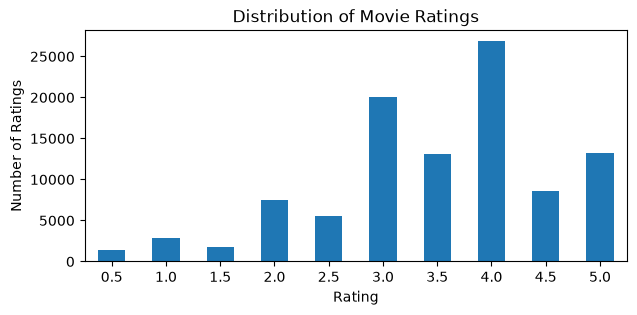

In [726]:
ratings['rating'].value_counts().sort_index().plot(kind='bar', figsize=(7, 3))

plt.title('Distribution of Movie Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Ratings')
plt.xticks(rotation=0)
plt.show()

In [727]:
print(ratings.info(), ratings.nunique())
# we have 18 movies w/o ratings

<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   userId     100836 non-null  int64         
 1   movieId    100836 non-null  int64         
 2   rating     100836 non-null  float64       
 3   timestamp  100836 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(1), int64(2)
memory usage: 3.1 MB
None userId         610
movieId       9724
rating          10
timestamp    85043
dtype: int64


In [728]:
movies['genres'].nunique()
movies['genres'].str.split('|').explode().unique()
movies['genres'].str.split('|').explode().value_counts()

genres
Drama                 4361
Comedy                3756
Thriller              1894
Action                1828
Romance               1596
Adventure             1263
Crime                 1199
Sci-Fi                 980
Horror                 978
Fantasy                779
Children               664
Animation              611
Mystery                573
Documentary            440
War                    382
Musical                334
Western                167
IMAX                   158
Film-Noir               87
(no genres listed)      34
Name: count, dtype: int64

In [729]:
movies['year'] = movies['title'].str.extract(r'\((\d{4})(?:–\d{4})?\)')
movies['original_title'] = movies['title']
movies['title'] = movies['title'].str.replace(r'\(\d{4}(?:–\d{4})?\)', '', regex=True)
movies['year'] = movies['year'].astype('Int16')

In [730]:
ratings_movies = ratings.merge(movies, how='left', on='movieId')
ratings_genres = ratings_movies.copy()
ratings_genres['genres'] = ratings_genres['genres'].str.split('|')
ratings_genres = ratings_genres.explode('genres')
ratings_genres = ratings_genres[ratings_genres['genres'] != '(no genres listed)']
genre_stats = ratings_genres.groupby('genres')['rating'].agg(['mean', 'count'])
genre_stats.sort_values('count', ascending=False)

,mean,count
genres,,
Drama,3.656184,41928
Comedy,3.384721,39053
Action,3.447984,30635
Thriller,3.493706,26452
Adventure,3.508609,24161
Romance,3.506511,18124
Sci-Fi,3.455721,17243
Crime,3.658294,16681
Fantasy,3.491001,11834


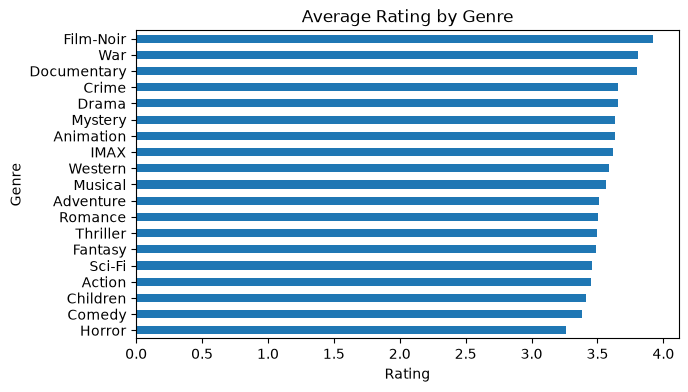

In [731]:
genre_stats.sort_values('mean').plot(kind='barh', y='mean', figsize=(7,4), legend=False)
plt.title("Average Rating by Genre")
plt.xlabel("Rating")
plt.ylabel("Genre")
plt.show()

In [732]:
print(ratings_movies['year'].isnull().sum())
ratings_movies[ratings_movies['year'].isna()]

17


,userId,movieId,rating,timestamp,title,genres,year,original_title
9147,62,176601,5.0,2018-05-08 16:00:52,Black Mirror,(no genres listed),<NA>,Black Mirror
16886,105,147250,5.0,2018-05-13 10:29:14,The Adventures of Sherlock Holmes and Doctor W...,(no genres listed),<NA>,The Adventures of Sherlock Holmes and Doctor W...
17879,111,171631,1.0,2018-01-31 23:21:49,Maria Bamford: Old Baby,(no genres listed),<NA>,Maria Bamford: Old Baby
17881,111,171891,3.5,2018-01-31 23:09:59,Generation Iron 2,(no genres listed),<NA>,Generation Iron 2
30039,209,140956,3.5,2018-04-23 22:23:59,Ready Player One,Action|Sci-Fi|Thriller,<NA>,Ready Player One
30090,210,40697,4.0,2018-05-25 16:36:31,Babylon 5,Sci-Fi,<NA>,Babylon 5
46593,305,140956,4.5,2018-07-31 13:26:17,Ready Player One,Action|Sci-Fi|Thriller,<NA>,Ready Player One
46711,306,149334,3.0,2018-02-11 20:19:32,Nocturnal Animals,Drama|Thriller,<NA>,Nocturnal Animals
49851,318,171495,5.0,2018-01-24 20:40:06,Cosmos,(no genres listed),<NA>,Cosmos
58040,380,140956,3.0,2018-08-13 16:02:38,Ready Player One,Action|Sci-Fi|Thriller,<NA>,Ready Player One


In [747]:
decade_stats = ratings_movies.groupby(ratings_movies['year'] // 10 * 10)['rating'].mean()
decade_stats = decade_stats.sort_index()
decade_stats.sort_values(ascending=False)

year
1940    3.870572
1950    3.845011
1960    3.808083
1970    3.775676
1920    3.740000
1930    3.733624
1980    3.518355
2010    3.488774
2000    3.465801
1990    3.434613
1900    3.312500
1910    3.312500
Name: rating, dtype: float64

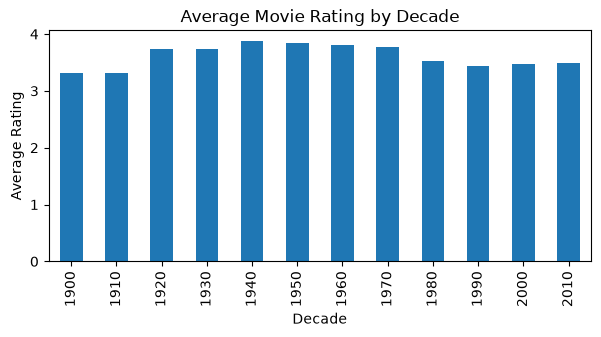

In [734]:
decade_stats.plot(kind='bar', figsize=(7,3))
plt.title('Average Movie Rating by Decade')
plt.xlabel('Decade')
plt.ylabel('Average Rating')
plt.show()

In [735]:
movie_stats = ratings_movies.groupby('movieId')['rating'].agg(['mean', 'count'])
movie_stats.sort_values('count', ascending=False)
movie_stats[movie_stats['count'] > 100].sort_values('mean', ascending=False).head(10)

,mean,count
movieId,,
318,4.429022,317
858,4.289062,192
2959,4.272936,218
1221,4.259690,129
48516,4.252336,107
1213,4.250000,126
58559,4.238255,149
50,4.237745,204
1197,4.232394,142


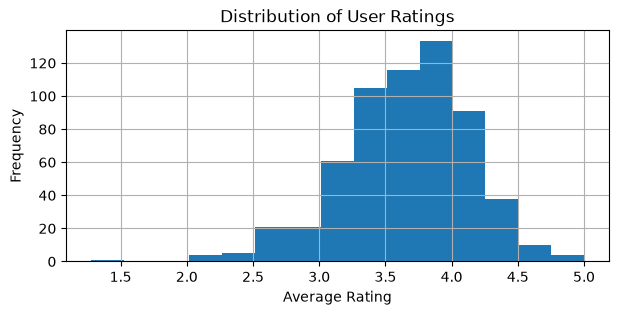

In [736]:
user_stats = ratings_movies.groupby('userId')['rating'].agg(['mean', 'count'])
#display(user_stats.sort_values('count', ascending=False))
#display(user_stats.sort_values('mean', ascending=False))
user_stats['mean'].hist(bins=15, figsize=(7,3))
plt.title("Distribution of User Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Frequency")
plt.show()

### Key Findings

1. The average movie rating is approximately **3.5 out of 5**, indicating that users tend to give moderately positive ratings.

2. **Drama, Comedy, and Action** are the most frequently rated genres.

3. **Film-Noir, War, and Documentary** have the highest average ratings. However, Film-Noir and Documentary have relatively fewer ratings (fewer than 1,220), so their averages should be interpreted cautiously.

4. Movies from the **1940s** have the highest average rating, while movies from the **1910s** have the lowest average rating.

5. The dataset contains **610 users**. Their average ratings vary considerably, showing that users have different rating habits and preferences.

6. Out of **9,742 movies**, 18 received no ratings. This means that most movies in the dataset have at least some user feedback.